In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [26]:
timeslipping = {'penguasaan': [6,10,14,28,40],
                'kesuksesan': [20,40,55.8,69,85]}

timeslip_df = pd.DataFrame(timeslipping)
timeslip_df

,penguasaan,kesuksesan
0,6,20.0
1,10,40.0
2,14,55.8
3,28,69.0
4,40,85.0


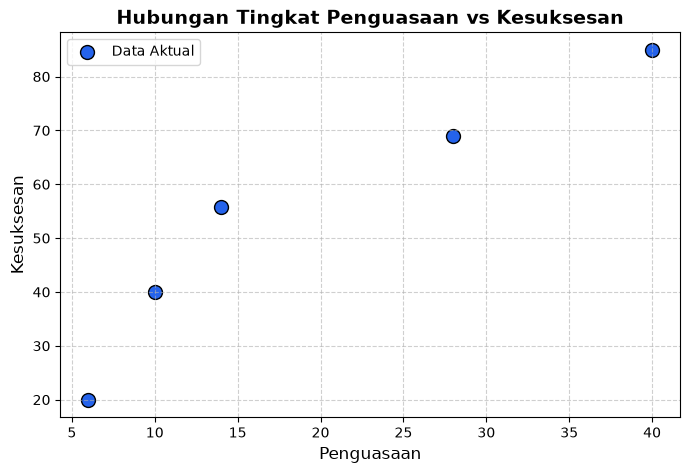

In [27]:

plt.figure(figsize=(8, 5))
plt.scatter(
    timeslip_df['penguasaan'], 
    timeslip_df['kesuksesan'], 
    color='#2563eb',          
    s=100,                     
    edgecolor='black',         
    label='Data Aktual'
)
plt.title('Hubungan Tingkat Penguasaan vs Kesuksesan', fontsize=14, fontweight='bold')
plt.xlabel('Penguasaan', fontsize=12)
plt.ylabel('Kesuksesan', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [28]:
X = np.array(timeslip_df['penguasaan'])
y = np.array(timeslip_df['kesuksesan'])

print(f'X:{X}')
print(f'y:{y}')

X:[ 6 10 14 28 40]
y:[20.  40.  55.8 69.  85. ]


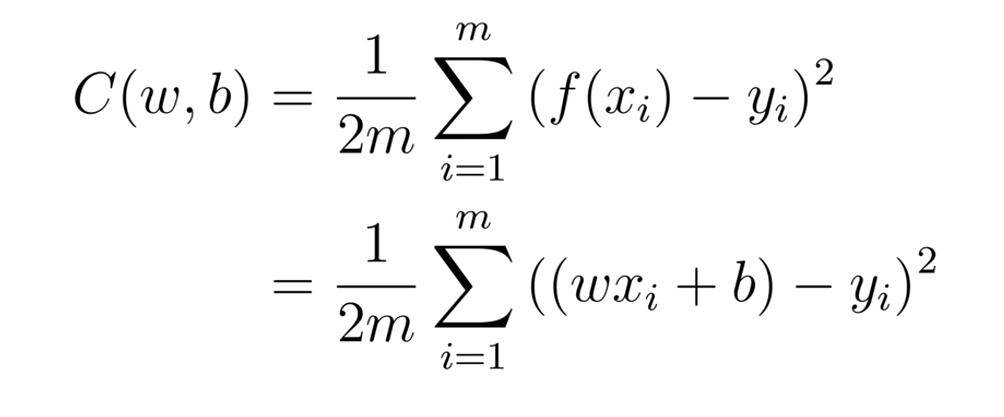

In [29]:
#membuat cost function
def cost_function (X,y,w,b):
    m_data_x = len(X)
    cost_sum = 0

    for i in range(m_data_x):
        fungsi_x = w * X[i] + b
        cost = (fungsi_x - y[i])**2

    total_cost = (1 /( 2*m_data_x)) * np.sum(cost)
    return total_cost



In [30]:
# membuat perhitungan gradien

def gradien_function (X,y,w,b):
    m_data_x = len(X)
    dc_dw = 0
    dc_db = 0

    for i in range(m_data_x):
        fungsi_x = w * X[i] + b
        dc_dw += (fungsi_x - y[i]) * X[i]
        dc_db += (fungsi_x - y[i])

    dc_dw = (1/m_data_x) * dc_dw
    dc_db = (1/m_data_x) * dc_db

    return dc_dw,dc_db

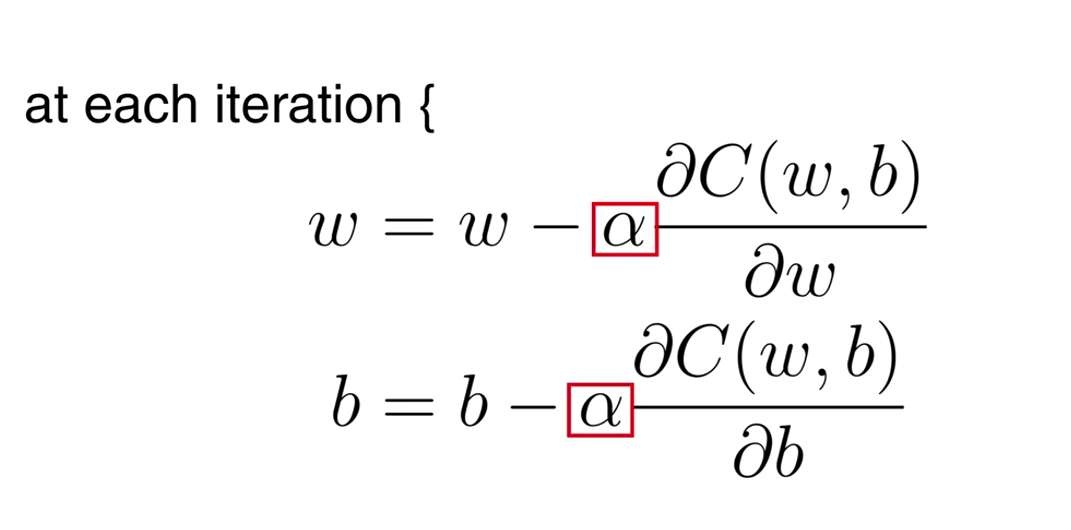

In [31]:
def gradien_descent(X, y, alpha, iterasi):

    w = 0
    b = 0

    for i in range(iterasi):
        dc_dw, dc_db = gradien_function(X,y,w,b)

        w = w - alpha * dc_dw
        b = b - alpha * dc_db

        if i % 1000 == 0:

            print(f"iterasi sekarang {i} cost {cost_function(X,y,w,b)}")

    return w, b


In [32]:

learning_rate = 0.001
iterasi = 1000000

akhir_w,akhir_b = gradien_descent( X, y, learning_rate, iterasi )

print(f"w : {akhir_w:4f} b : {akhir_b:4f}")

iterasi sekarang 0 cost 101.63624545935996
iterasi sekarang 1000 cost 10.676970576215957
iterasi sekarang 2000 cost 7.382487966111107
iterasi sekarang 3000 cost 5.318410226992071
iterasi sekarang 4000 cost 3.997812933201472
iterasi sekarang 5000 cost 3.1347065505025355
iterasi sekarang 6000 cost 2.558781002753305
iterasi sekarang 7000 cost 2.166959598574763
iterasi sekarang 8000 cost 1.8957014209476357
iterasi sekarang 9000 cost 1.7050428505157673
iterasi sekarang 10000 cost 1.5693131917757752
iterasi sekarang 11000 cost 1.4716684978321153
iterasi sekarang 12000 cost 1.4008271212044978
iterasi sekarang 13000 cost 1.3490874927759176
iterasi sekarang 14000 cost 1.3111017425246836
iterasi sekarang 15000 cost 1.2831013726977762
iterasi sekarang 16000 cost 1.2623978812670051
iterasi sekarang 17000 cost 1.2470538075477728
iterasi sekarang 18000 cost 1.2356615917327813
iterasi sekarang 19000 cost 1.2271921041851108
iterasi sekarang 20000 cost 1.2208891577649892
iterasi sekarang 21000 cost 1.2

KeyboardInterrupt: 

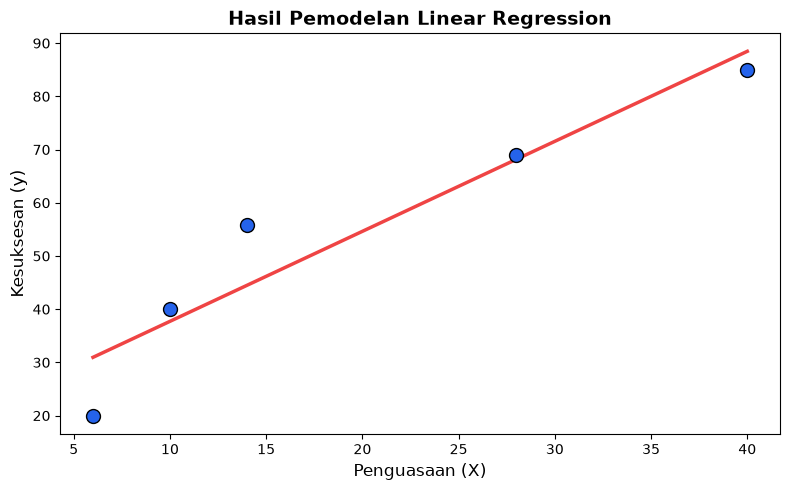

In [ ]:
y_prediksi = akhir_w * X + akhir_b
plt.figure(figsize=(8, 5))

plt.scatter(
    X, y, 
    color='#2563eb', 
    s=100, 
    edgecolor='black', 
    zorder=3,
    label='Data Aktual'
)

plt.plot(
    X, y_prediksi, 
    color='#ef4444', 
    linewidth=2.5, 
    label=f'Garis Model: y = {akhir_w:.2f}x + {akhir_b:.2f}'
)
plt.title('Hasil Pemodelan Linear Regression', fontsize=14, fontweight='bold')
plt.xlabel('Penguasaan (X)', fontsize=12)
plt.ylabel('Kesuksesan (y)', fontsize=12)
plt.tight_layout()
plt.show()

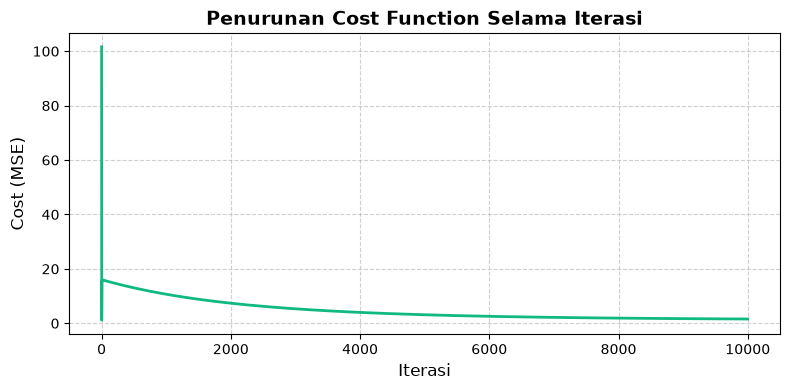

In [ ]:
def gradien_descent(X, y, alpha, iterasi):
    w = 0.0
    b = 0.0
    cost_history = []
    for i in range(iterasi):
        dc_dw, dc_db = gradien_function(X, y, w, b)
        w = w - alpha * dc_dw
        b = b - alpha * dc_db
        
        
        cost_history.append(cost_function(X, y, w, b))
    return w, b, cost_history

akhir_w, akhir_b, cost_history = gradien_descent(X, y, 0.001, 10000)

plt.figure(figsize=(8, 4))
plt.plot(cost_history, color='#10b981', linewidth=2)
plt.title('Penurunan Cost Function Selama Iterasi', fontsize=14, fontweight='bold')
plt.xlabel('Iterasi', fontsize=12)
plt.ylabel('Cost (MSE)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Mencari intercept dengan menyelisihkan rata2 y dan slope di kali dengan rata2 x

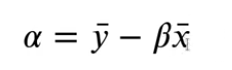

pembagian antara covariance dari x dan y dan juga variance dari x dan y

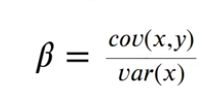

variance : Mengukur seberapa jauh data tersebar dari nilai rata-ratanya
covariance : Mengukur seberapa besar dua variabel berubah bersama-sama 

slope : tingkat kemiringan
intercept : nilai pada sumbu y pada sumbu x ketika bernilai 0

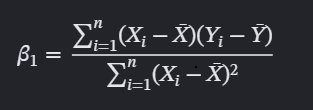

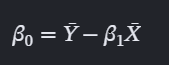

In [ ]:
rata2_X = X - np.mean(X)
rata2_y = y - np.mean(y)

slope = np.sum(rata2_X * rata2_y) / np.sum(rata2_X**2)
intercept = np.mean(y) - slope * np.mean(X)

print(slope,intercept)

1.6915492957746476 20.805633802816907


In [33]:
y_hat = intercept + slope * X

print(y_hat)

[30.95492958 37.72112676 44.48732394 68.16901408 88.46760563]
